# 05 · Showcase

Results of the n-tuple network: learning curves from the training logs (A), then evaluation
and replays (B, added later). All logic lives in `src/analysis/`; this notebook only calls it.

In [1]:
%load_ext autoreload
%autoreload 2

import platform

from analysis import curves

assert platform.machine() == "arm64", platform.machine()

## A · Learning curves

Reads `logs/<run>.csv` for the three overnight runs (one row per 1,000 games); no training or
evaluation. Raw rows are drawn faintly, a trailing `WINDOW`-row mean on top (20 rows = the
last 20k games); the log-x plot uses log-binned means instead. Every figure is saved to
`figures/` as PNG and SVG.

figures/curves_avg_score_vs_games.png  figures/curves_avg_score_vs_games.svg
figures/curves_avg_score_vs_games_logx.png  figures/curves_avg_score_vs_games_logx.svg
figures/curves_reach_rates_vs_games.png  figures/curves_reach_rates_vs_games.svg
figures/curves_avg_moves_vs_games.png  figures/curves_avg_moves_vs_games.svg
figures/curves_max_score_vs_games.png  figures/curves_max_score_vs_games.svg
figures/curves_avg_score_vs_hours.png  figures/curves_avg_score_vs_hours.svg


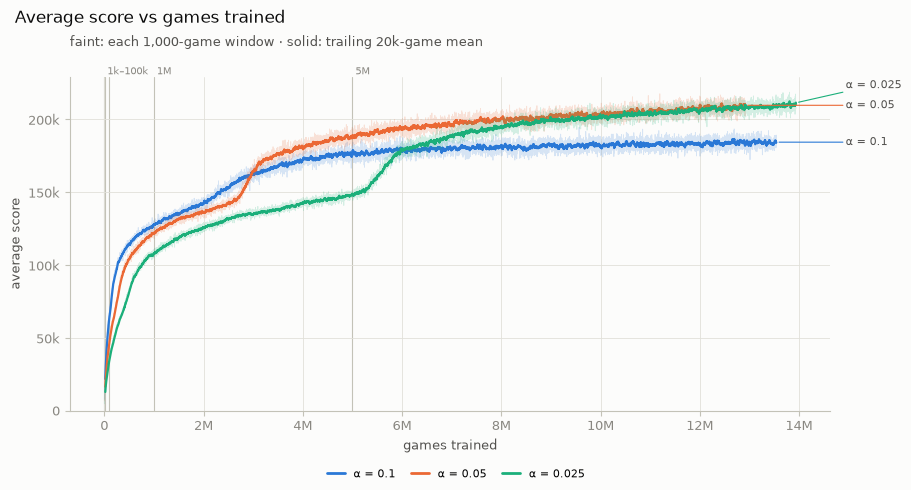

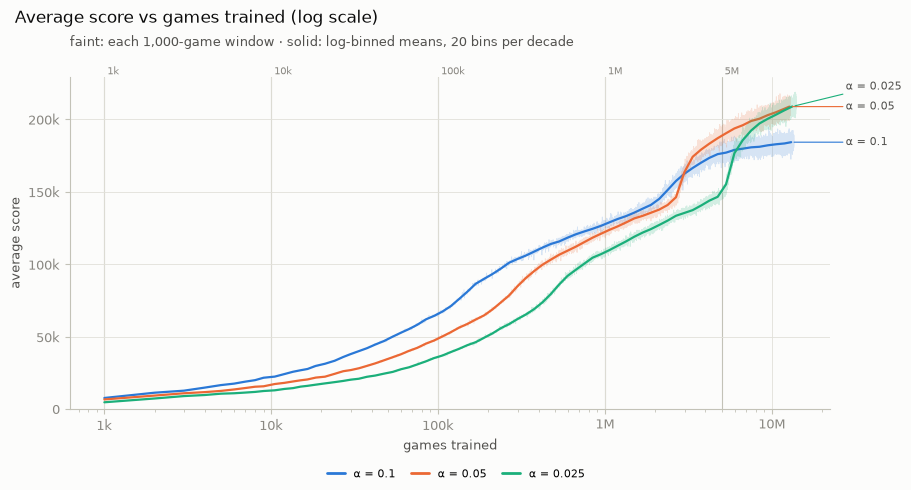

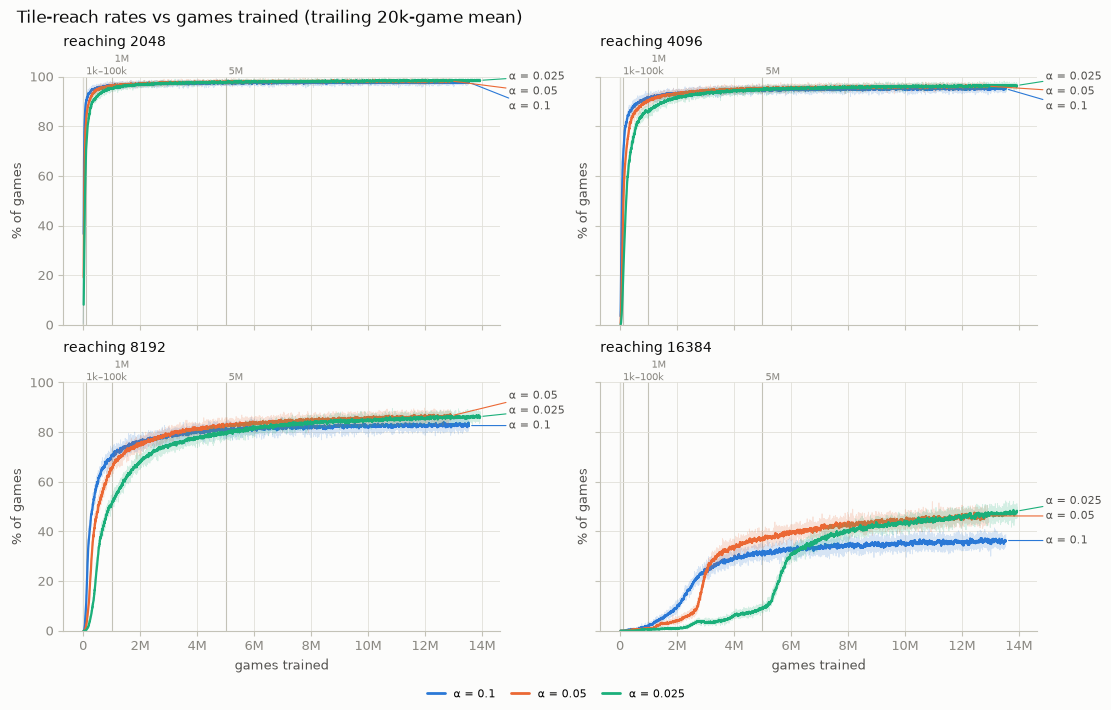

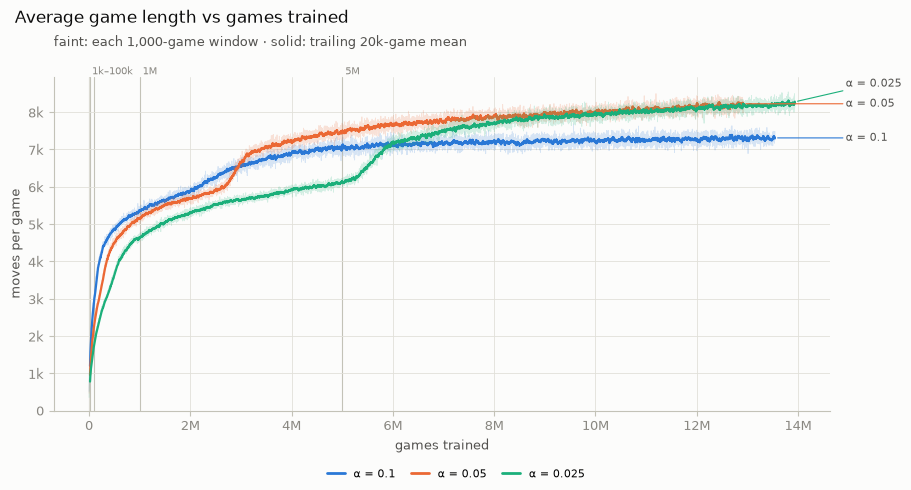

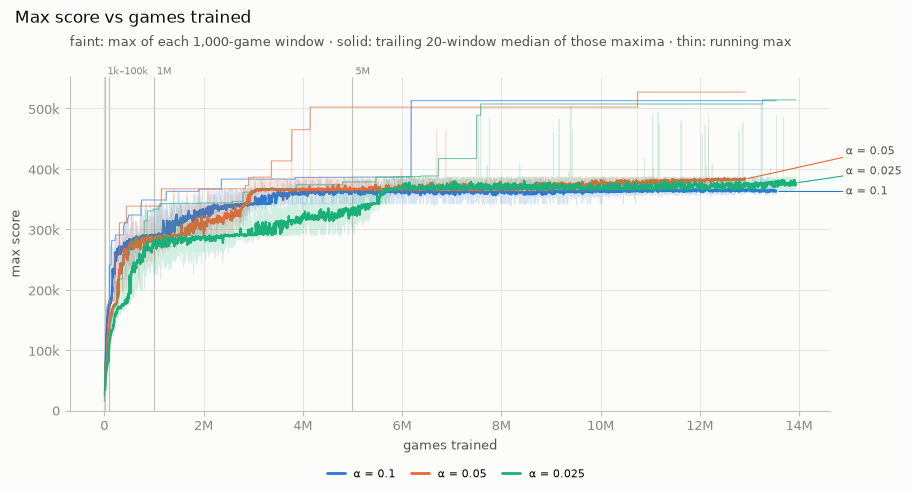

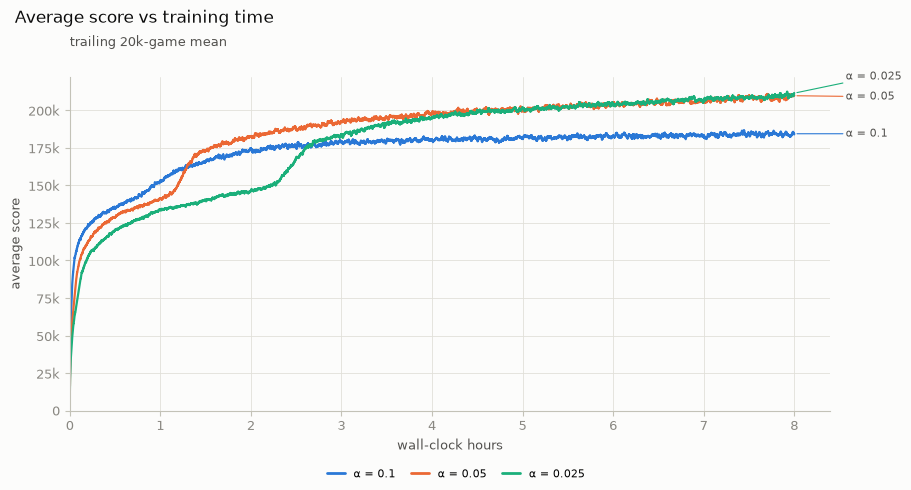

In [2]:
WINDOW = 20  # rows of 1,000 games

figs, table = curves.make_all(window=WINDOW)
for name in figs:
    print(f"figures/{name}.png  figures/{name}.svg")

Per run: averages over the last `WINDOW` rows, and the first game count at which the trailing
`WINDOW`-row mean of the 16384 reach rate exceeded 20%.

In [3]:
print(curves.format_summary(table))

last 20 rows (20k games); reach = % of games reaching the tile
run               alpha       games  hours  avg score   2048   4096   8192  16384   16384 > 20% first at
overnight-a01       0.1  13,541,000   8.00    184,274  97.7%  95.1%  82.6%  36.3%   2,607,000 games (1.08 h)
overnight-a005     0.05  12,912,000   8.00    209,571  98.2%  96.2%  86.5%  46.2%   2,930,000 games (1.27 h)
overnight-a0025   0.025  13,936,000   8.00    211,269  98.5%  96.4%  86.3%  48.2%   5,571,000 games (2.45 h)


## B · Evaluation

Reads `results/eval/` (written by `python -m ntuple.evaluate`, see `TRAINING.md`); no games are
played here. Policies: `random`, `greedy` (expectimax depth 0, the training policy) and
`expectimax-d1/d2/d3` (depth = chance layers; d1 and d2 are exact, d3 prunes branches with
reach probability < 1e-4). Game i uses seed i for every policy and checkpoint. Intervals are
95%: mean ± 1.96·s/√n for scores, Wilson for reach rates.

In [ ]:
from analysis import report, stats

table = report.summary()
cols = ["run", "checkpoint", "games_trained", "policy", "depth", "games", "mean_score",
        "mean_lo", "mean_hi", "reach_8192", "reach_16384", "reach_32768", "corner_pct",
        "ms_per_move"] + [c for c in ["ms_per_move_bench"] if c in table]
table[cols].round(2) if len(table) else print("no results in results/eval yet")

### Which run is the main model

Greedy on the final checkpoints, paired by seed: score difference (95% CI) and 16384-rate
difference are reported together; if they point in opposite directions it says DISAGREE and
the choice is left to a human.

In [ ]:
print(stats.format_comparison(report.compare("overnight-a005", "overnight-a0025")))

### Strength vs games trained

Greedy at every milestone plus the final checkpoint (the last point, hollow marker).

In [ ]:
fig = report.plot_progression(table)
curves.save_figure(fig, "eval_progression_greedy");

### Main model: max tile and search cost

`MAIN_RUN` is the run confirmed after the comparison above.

In [ ]:
MAIN_RUN = "overnight-a005"  # set to the confirmed winner

fig = report.plot_max_tile_distribution(table, MAIN_RUN)
curves.save_figure(fig, f"eval_max_tile_{MAIN_RUN}")
fig = report.plot_strength_vs_cost(table, MAIN_RUN)
curves.save_figure(fig, f"eval_strength_vs_cost_{MAIN_RUN}");

## C · Replays

Files in `results/replays/` (written by `python -m ntuple.replays`); drag the slider to step
through a game.

In [ ]:
from ntuple.replays import REPLAY_ROOT

replays = sorted(REPLAY_ROOT.glob("*.json"))
for i, p in enumerate(replays):
    print(i, p.name)

In [ ]:
report.replay_viewer(replays[0]);